# ML1 — Phân khúc khách hàng bằng RFM + K-Means

**Loại bài toán:** phân cụm (clustering) — không có nhãn VIP/Normal sẵn nên dùng học không giám sát, **không báo Accuracy**.

**Quy trình (mục 6 của tài liệu hướng dẫn):**
1. Lấy `customer_id, packing_date, goods_amount, order_id` từ `dw.fact_sales` (hoặc dựng lại từ Excel).
2. Tính **R** = ngày tham chiếu − ngày mua gần nhất · **F** = số đơn khác nhau · **M** = tổng `goods_amount`. Ngày tham chiếu là *ngày sau đơn cuối trong dữ liệu*, không phải hôm nay.
3. Biến đổi `R`, `log1p(F)`, `log1p(M)` → `StandardScaler`.
4. Thử K = 2..6, đánh giá **silhouette + kích thước cụm + độ ổn định theo seed**.
5. Đặt tên cụm *sau khi* xem tâm cụm; so với baseline RFM-quantile.

> Notebook này dùng đúng mã của `ml1_rfm_kmeans.py` (các hàm được sao nguyên văn), chỉ tách thành từng bước để dễ đọc và trình bày.

In [ ]:
from __future__ import annotations
import sys, itertools, json
from pathlib import Path
from datetime import datetime, timezone
import os
from dotenv import load_dotenv

# Thư viện xử lý dữ liệu và Machine Learning
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score
from sklearn.preprocessing import StandardScaler

# Thư viện kết nối Database
from sqlalchemy import create_engine

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

# 1. Cấu hình Database (Thay cho SOURCE = "auto" và load_sales)
DB_USER = os.getenv("POSTGRES_USER")  # Đổi thành user của bạn
DB_PASSWORD = os.getenv("POSTGRES_PASSWORD")  # Đổi thành mật khẩu của bạn
DB_HOST = 'localhost' 
DB_PORT = '5433'
DB_NAME = os.getenv("POSTGRES_DB", "ecom_dwh")  # Đổi thành tên db của bạn

engine = create_engine(f'postgresql://{DB_USER}:{DB_PASSWORD}@{DB_HOST}:{DB_PORT}/{DB_NAME}')

# 2. Cấu hình thư mục output (Thay cho OUT_DIR import từ common)
OUT_DIR = Path.cwd() / "outputs" / "nb" / 'ml1'
OUT_DIR.mkdir(parents=True, exist_ok=True)

# 3. Các tham số thuật toán (Giữ nguyên)
SAVE = True         # True: ghi kết quả vào outputs/nb/
SEEDS = list(range(10))
K_RANGE = range(2, 7)
MIN_CLUSTER_SHARE = 0.05   # cụm nhỏ hơn 5% khách bị xem là kém ý nghĩa vận hành
MIN_STABILITY_ARI = 0.90   # ARI trung bình giữa các seed phải >= 0.90



## 1. Dữ liệu

In [ ]:
# --- LẤY DỮ LIỆU ---
query = 'SELECT c.customer_id,d.full_date AS packing_date,s.goods_amount,s.order_id \
FROM dw.fact_sales s JOIN dw.dim_customer c ON c.customer_key=s.customer_key \
JOIN dw.dim_date d ON d.date_key=s.date_key;'
sales = pd.read_sql(query, engine)
display(sales.head())

,customer_id,packing_date,goods_amount,order_id
0,KH000289,2022-02-12,18000000.0,DH000036
1,KH001923,2022-10-01,6800000.0,DH000065
2,KH001512,2023-04-25,8500000.0,DH000423
3,KH002499,2023-08-10,52500000.0,DH000037
4,KH000743,2022-12-03,52000000.0,DH000058


In [65]:
display(sales['customer_id'].count)

<bound method Series.count of 0       KH000289
1       KH001923
2       KH001512
3       KH002499
4       KH000743
          ...   
9995    KH001434
9996    KH001163
9997    KH001985
9998    KH002656
9999    KH001560
Name: customer_id, Length: 10000, dtype: object>

## 2. Tính RFM

Bước đầu: ép kiểu dữ liệu đọc từ Postgres. Cột `DATE` của `dw.dim_date.full_date` về pandas dưới dạng `datetime.date` (dtype `object`), nên phải đổi sang `datetime64` thì mới dùng được `.dt` và phép trừ ngày.

Sau đó kiểm tra chất lượng (null, `goods_amount` âm) và tính R/F/M cho từng khách.

In [54]:
# Ép kiểu: Postgres trả cột DATE về datetime.date (dtype object) -> đổi sang datetime64 để dùng được .dt
sales = sales.copy()
sales["packing_date"] = pd.to_datetime(sales["packing_date"])
sales["goods_amount"] = pd.to_numeric(sales["goods_amount"])      # phòng trường hợp trả về Decimal
print(sales.dtypes.to_dict())

qa = {"rows_in": len(sales)}
df = sales.dropna(subset=["customer_id", "order_id", "goods_amount", "packing_date"])
qa["dropped_null"] = qa["rows_in"] - len(df)
qa["negative_goods_amount"] = int((df["goods_amount"] < 0).sum())
df = df[df["goods_amount"] >= 0]

ref = df["packing_date"].max() + pd.Timedelta(days=1)      # KHÔNG dùng ngày hôm nay
g = df.groupby("customer_id")
rfm = pd.DataFrame({
    "recency_days": (ref - g["packing_date"].max()).dt.days,
    "frequency": g["order_id"].nunique(),
    "monetary": g["goods_amount"].sum(),
}).reset_index()
qa.update(customers=len(rfm), reference_date=str(ref.date()))
print(qa)
rfm.describe().round(1)

{'customer_id': dtype('O'), 'packing_date': dtype('<M8[ns]'), 'goods_amount': dtype('float64'), 'order_id': dtype('O')}
{'rows_in': 10000, 'dropped_null': 0, 'negative_goods_amount': 0, 'customers': 3282, 'reference_date': '2025-12-21'}


,recency_days,frequency,monetary
count,3282.0,3282.0,3.282000e+03
mean,740.6,3.0,1.883893e+08
std,598.0,2.9,2.235516e+08
min,1.0,1.0,8.500000e+05
25%,228.0,1.0,3.952500e+07
50%,590.0,2.0,1.053000e+08
75%,1172.0,4.0,2.591750e+08
max,2181.0,20.0,1.698300e+09


## 3. Biến đổi và chuẩn hoá

F và M lệch phải mạnh, nên lấy `log1p` để K-Means (dựa trên khoảng cách Euclid) không bị vài khách chi rất nhiều kéo lệch.

Skewness: {'F_raw': 2.21, 'logF': 0.92, 'M_raw': 2.34, 'logM': -0.46}


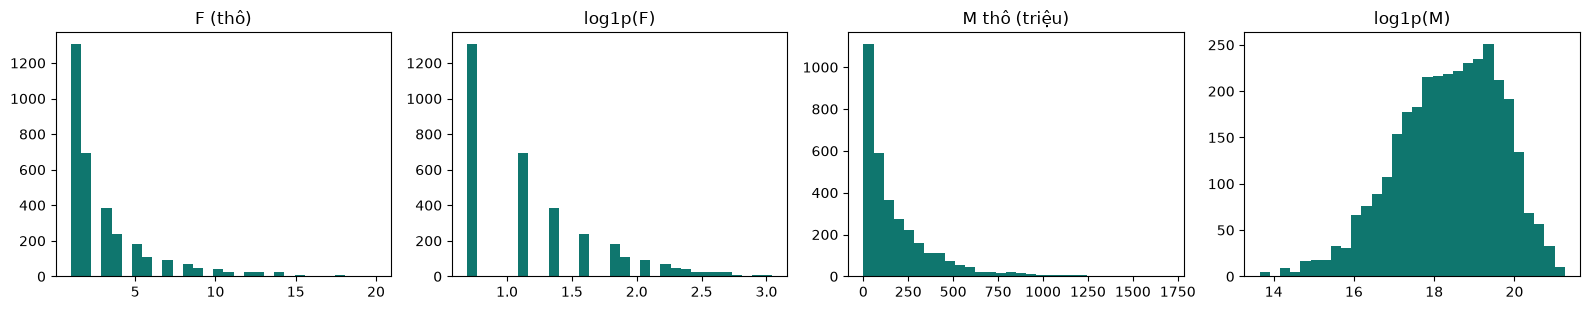

In [55]:
feats = pd.DataFrame({"R": rfm["recency_days"], "logF": np.log1p(rfm["frequency"]), "logM": np.log1p(rfm["monetary"])})
skew = {"F_raw": rfm.frequency.skew(), "logF": feats.logF.skew(), "M_raw": rfm.monetary.skew(), "logM": feats.logM.skew()}
print("Skewness:", {k: round(float(v), 2) for k, v in skew.items()})

fig, ax = plt.subplots(1, 4, figsize=(16, 3.2))
for a, (s, t) in zip(ax, [(rfm.frequency, "F (thô)"), (feats.logF, "log1p(F)"), (rfm.monetary / 1e6, "M thô (triệu)"), (feats.logM, "log1p(M)")]):
    a.hist(s, bins=30, color="#0f766e"); a.set_title(t)
fig.tight_layout(); plt.show()

scaler = StandardScaler().fit(feats)
X = scaler.transform(feats)

## 4. Chọn số cụm K

Với mỗi K = 2..6: silhouette, Davies-Bouldin, tỷ lệ cụm nhỏ nhất, và **độ ổn định** (ARI trung bình giữa 10 lần chạy với seed khác nhau).

**Quy tắc chọn K (đặt trước khi xem kết quả):** silhouette cao nhất trong các K ≥ 3 thoả *cụm nhỏ nhất ≥ 5%* và *ARI ≥ 0,90*. K = 2 chỉ tách "tốt / xấu" nên ít giá trị phân khúc — đây là lựa chọn có chủ ý, bạn có thể gán `K` thủ công ở ô sau.

In [56]:
def fit_k(X: np.ndarray, k: int, seed: int = 42) -> KMeans:
    return KMeans(n_clusters=k, n_init=20, random_state=seed).fit(X)


def evaluate_k(X: np.ndarray) -> pd.DataFrame:
    rows = []
    for k in K_RANGE:
        main = fit_k(X, k)
        labels = main.labels_
        share = np.bincount(labels, minlength=k) / len(labels)
        seed_labels = [KMeans(n_clusters=k, n_init=20, random_state=s).fit_predict(X) for s in SEEDS]
        ari = np.mean([adjusted_rand_score(a, b) for a, b in itertools.combinations(seed_labels, 2)])
        rows.append(
            dict(k=k, silhouette=silhouette_score(X, labels), davies_bouldin=davies_bouldin_score(X, labels),
                 inertia=main.inertia_, min_cluster_share=share.min(), seed_stability_ari=ari)
        )
    return pd.DataFrame(rows)


def choose_k(table: pd.DataFrame) -> int:
    ok = table[(table.min_cluster_share >= MIN_CLUSTER_SHARE) & (table.seed_stability_ari >= MIN_STABILITY_ARI)]
    pool = ok if len(ok) else table
    # K=2 chỉ tách "tốt/xấu" - ít giá trị phân khúc; ưu tiên K>=3 nếu còn K hợp lệ.
    pool3 = pool[pool.k >= 3]
    pool = pool3 if len(pool3) else pool
    return int(pool.sort_values("silhouette", ascending=False).iloc[0].k)

In [57]:
table = evaluate_k(X)
table.round(3)

,k,silhouette,davies_bouldin,inertia,min_cluster_share,seed_stability_ari
0,2,0.402,0.935,5076.820,0.454,0.998
1,3,0.352,1.023,3573.210,0.295,0.993
2,4,0.333,0.986,2790.524,0.203,0.993
3,5,0.328,0.959,2293.940,0.141,0.988
4,6,0.294,1.048,2015.060,0.122,0.977


Chọn K = 3


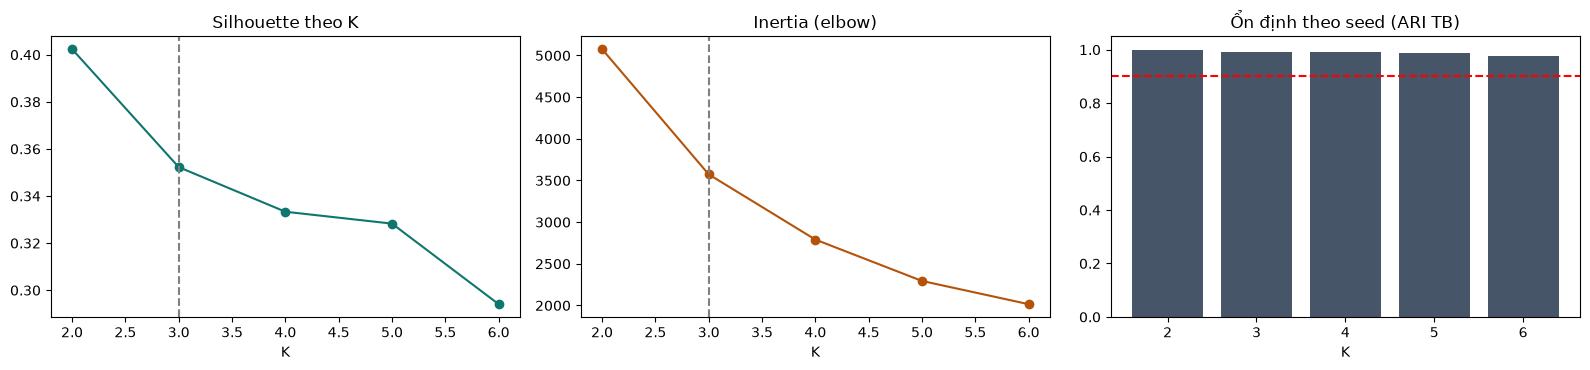

In [58]:
K = choose_k(table)        # hoặc gán thủ công, ví dụ K = 4
print("Chọn K =", K)

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
ax[0].plot(table.k, table.silhouette, "o-", color="#0f766e"); ax[0].axvline(K, ls="--", c="grey"); ax[0].set(title="Silhouette theo K", xlabel="K")
ax[1].plot(table.k, table.inertia, "o-", color="#b45309"); ax[1].axvline(K, ls="--", c="grey"); ax[1].set(title="Inertia (elbow)", xlabel="K")
ax[2].bar(table.k, table.seed_stability_ari, color="#475569"); ax[2].axhline(MIN_STABILITY_ARI, ls="--", c="red")
ax[2].set(title="Ổn định theo seed (ARI TB)", xlabel="K", ylim=(0, 1.05))
fig.tight_layout(); plt.show()

## 5. Mô hình cuối và diễn giải cụm

Thống kê mỗi cụm dùng **trung vị** (chống lệch phải). Tên cụm được đặt từ tâm cụm (z-score R/logF/logM) — *không* mặc định cluster 0 = VIP.

In [59]:
def name_segments(summary: pd.DataFrame) -> dict[int, str]:
    """Đặt tên SAU KHI xem tâm cụm (z-score R/logF/logM), không mặc định cluster 0 = VIP.

    Tên = bậc giá trị (xếp theo điểm tổng hợp  -R_z + logF_z + logM_z) + mô tả hành vi khi lệch rõ (|z| > 0.5).
    """
    comp = -summary["R_z"] + summary["logF_z"] + summary["logM_z"]
    order = comp.sort_values(ascending=False).index.tolist()
    names = {}
    for rank, cid in enumerate(order):
        r = summary.loc[cid]
        tier = "Giá trị cao" if rank == 0 else ("Giá trị thấp" if rank == len(order) - 1 else "Giá trị trung bình")
        tags = []
        if r.logF_z > 0.5: tags.append("mua thường xuyên")
        elif r.logF_z < -0.5: tags.append("mua ít")
        if r.R_z < -0.5: tags.append("mua gần đây")
        elif r.R_z > 0.5: tags.append("lâu không quay lại")
        names[cid] = " – ".join([tier] + tags)
    dup = {}
    for cid, n in names.items():
        dup.setdefault(n, []).append(cid)
    for n, ids in dup.items():
        if len(ids) > 1:
            for i, cid in enumerate(sorted(ids), 1):
                names[cid] = f"{n} ({i})"
    return names

In [60]:
km = fit_k(X, K)
rfm["cluster_id"] = km.labels_

g = rfm.groupby("cluster_id")
summary = pd.DataFrame({
    "customers": g.size(),
    "customer_share": g.size() / len(rfm),
    "recency_days": g.recency_days.median(),
    "frequency": g.frequency.median(),
    "monetary": g.monetary.median(),
    "mean_monetary": g.monetary.mean(),
    "revenue_share": g.monetary.sum() / rfm.monetary.sum(),
})
centers = pd.DataFrame(km.cluster_centers_, columns=["R_z", "logF_z", "logM_z"], index=summary.index)
summary = summary.join(centers)
summary["segment_name"] = pd.Series(name_segments(summary))
rfm["segment_name"] = rfm.cluster_id.map(summary.segment_name)
summary.round(3)

,customers,customer_share,recency_days,frequency,monetary,mean_monetary,revenue_share,R_z,logF_z,logM_z,segment_name
cluster_id,,,,,,,,,,,
0,1335,0.407,471.0,2.0,78000000.0,1.052685e+08,0.227,-0.414,-0.358,-0.202,Giá trị trung bình
1,968,0.295,226.0,5.0,357400000.0,4.277799e+08,0.670,-0.715,1.285,1.026,Giá trị cao – mua thường xuyên – mua gần đây
2,979,0.298,1479.0,1.0,35200000.0,6.503524e+07,0.103,1.271,-0.781,-0.737,Giá trị thấp – mua ít – lâu không quay lại


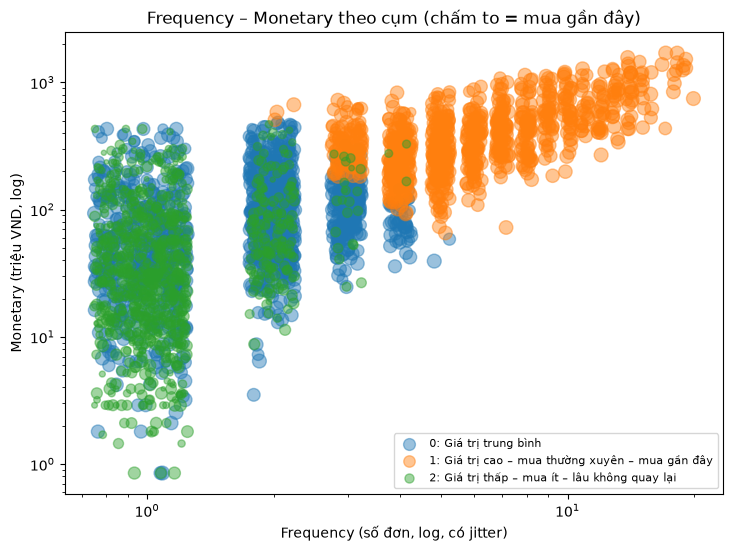

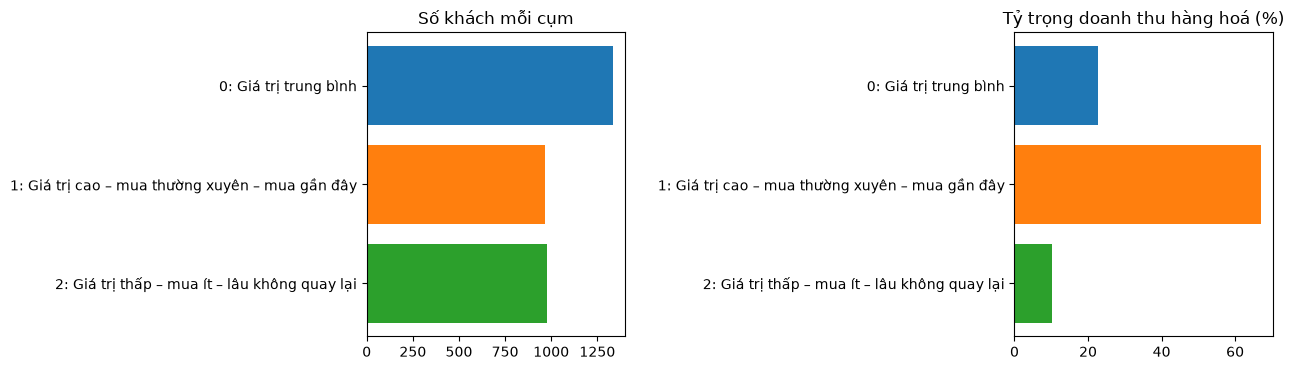

In [61]:
rng = np.random.default_rng(0)
cmap = plt.get_cmap("tab10")
fig, ax = plt.subplots(figsize=(8.5, 6))
for cid, sub in rfm.groupby("cluster_id"):
    jx = sub.frequency + rng.uniform(-0.25, 0.25, len(sub))
    size = 10 + 90 * (1 - sub.recency_days / rfm.recency_days.max())      # chấm to = mua gần đây
    ax.scatter(jx, sub.monetary / 1e6, s=size, alpha=0.45, color=cmap(cid), label=f"{cid}: {sub.segment_name.iloc[0]}")
ax.set(xscale="log", yscale="log", xlabel="Frequency (số đơn, log, có jitter)", ylabel="Monetary (triệu VND, log)",
       title="Frequency – Monetary theo cụm (chấm to = mua gần đây)")
ax.legend(fontsize=8, loc="lower right"); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
labels = [f"{i}: {n}" for i, n in zip(summary.index, summary.segment_name)]
ax[0].barh(labels, summary.customers, color=[cmap(i) for i in summary.index]); ax[0].set(title="Số khách mỗi cụm"); ax[0].invert_yaxis()
ax[1].barh(labels, summary.revenue_share * 100, color=[cmap(i) for i in summary.index]); ax[1].set(title="Tỷ trọng doanh thu hàng hoá (%)"); ax[1].invert_yaxis()
fig.tight_layout(); plt.show()

## 6. So với baseline và kiểm tra độ ổn định

- **Baseline RFM-quantile:** chấm điểm R/F/M theo quintile rồi chia K nhóm theo tổng điểm. *Lưu ý:* silhouette tính trong chính không gian K-Means tối ưu nên nghiêng về K-Means; ARI cho biết hai cách chia khác nhau đến đâu.
- **Giữ lại 20%:** fit trên 80% khách, gán 20% còn lại, so với mô hình đầy đủ.

In [62]:
def quantile_segments(rfm: pd.DataFrame, k: int) -> np.ndarray:
    """Baseline đơn giản: điểm RFM theo quintile (rank để xử lý nhiều giá trị F bằng nhau), rồi chia k nhóm."""
    score = lambda s, asc: pd.qcut(s.rank(method="first", ascending=asc), 5, labels=False) + 1  # noqa: E731
    total = score(rfm["recency_days"], False) + score(rfm["frequency"], True) + score(rfm["monetary"], True)
    return pd.qcut(total.rank(method="first"), k, labels=False).to_numpy()

In [63]:
q_labels = quantile_segments(rfm, K)
base = {
    "kmeans_silhouette": float(silhouette_score(X, km.labels_)),
    "quantile_silhouette": float(silhouette_score(X, q_labels)),
    "ARI_kmeans_vs_quantile": float(adjusted_rand_score(km.labels_, q_labels)),
}
rng = np.random.default_rng(42); idx = rng.permutation(len(X)); cut = int(0.8 * len(X))
sub = fit_k(X[idx[:cut]], K)
base["holdout20_agreement_ARI"] = float(adjusted_rand_score(km.labels_[idx[cut:]], sub.predict(X[idx[cut:]])))
pd.Series(base).round(3)

kmeans_silhouette          0.352
quantile_silhouette        0.261
ARI_kmeans_vs_quantile     0.494
holdout20_agreement_ARI    0.957
dtype: float64

## 7. Kết luận

- **K = 3**, rất ổn định giữa các seed (ARI ≈ 0,99) và khi chỉ thấy 80% khách (ARI ≈ 0,96).
- Cụm **"Giá trị cao – mua thường xuyên – mua gần đây"** chỉ chiếm ~30% khách nhưng tạo ra ~67% doanh thu hàng hoá.
- Cụm **"Giá trị thấp – mua ít – lâu không quay lại"** (~30% khách, ~10% doanh thu) có recency trung vị ~4 năm.

**Hạn chế cần nói khi trình bày**
- Cụm 0 và cụm 2 chồng nhau nhiều ở F = 1; hai cụm này tách nhau chủ yếu theo recency.
- Nhóm "khách mới, chỉ mua một đơn" (ví dụ trong tài liệu) **không xuất hiện**: ngày mua của khách một đơn rải đều trong 6 năm nên phần lớn là khách đã nguội.
- `monetary` là tiền hàng mô phỏng, không phải lợi nhuận. Đặt tên cụm là diễn giải của con người, không phải kết quả thống kê.

## 8. (Tuỳ chọn) Lưu kết quả

Đặt `SAVE = True` ở ô đầu để ghi ra thư mục `outputs/nb/` (cạnh notebook). Kết quả chính thức của pipeline do `ml1_rfm_kmeans.py` tạo (`--persist` để ghi vào `ml.customer_segments`).

In [64]:
SAVE = True
if SAVE:
    out_dir = OUT_DIR; out_dir.mkdir(parents=True, exist_ok=True)   # OUT_DIR đã là outputs/nb
    version = f"rfm_kmeans_k{K}_{datetime.now(timezone.utc):%Y%m%d}"
    out = rfm.assign(model_version=version, scored_at=datetime.now(timezone.utc).isoformat(timespec="seconds"))
    out[["customer_id", "cluster_id", "segment_name", "recency_days", "frequency", "monetary", "model_version", "scored_at"]].to_csv(
        out_dir / "ml1_customer_segments.csv", index=False, encoding="utf-8-sig")
    summary.round(4).to_csv(out_dir / "ml1_cluster_summary.csv", encoding="utf-8-sig")
    table.round(4).to_csv(out_dir / "ml1_k_selection.csv", index=False)
    joblib.dump({"scaler": scaler, "kmeans": km, "model_version": version}, out_dir / "ml1_model.joblib")
    print("Đã lưu vào", out_dir)
else:
    print("SAVE = False -> không ghi file.")

Đã lưu vào w:\Khánh\LAK_Khodulieu\mining\outputs\nb\ml1
